# U2 AquaVigía: evaluación del riesgo (curva ROC) y curva de aprendizaje

Dimensión U2 de **Jhenderson Aaron Machaca Mamani**: pH y turbidez. Complementa al 12b; no cambia el modelo ni el pipeline.

| Pregunta | Herramienta |
|---|---|
| ¿El **riesgo** que emite el modelo separa bien las horas en que el agua sale de su rango de las que no? | **Curva ROC y AUC** del riesgo, frente a lo que realmente pasó una hora después |
| ¿Más datos de entrenamiento mejorarían el pronóstico? | **Curva de aprendizaje**: RMSE según cuántos datos se usan para entrenar |

El pronóstico es una **regresión** (un valor), así que la ROC no se aplica al valor. Se aplica al **riesgo**, que es una probabilidad de salir del rango: eso sí es un clasificador.

In [2]:
import os, json, math, subprocess, sys
import pandas as pd
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StringType, DoubleType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
try:
    import matplotlib
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib"], check=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

INTEGRANTE = "Jhenderson Machaca"
ID = "jhenderson"
VARIABLES = ["ph", "turbidez_fnu"]
BASE = "/opt/s12-u2-usgs"
ARTIFACTS = f"{BASE}/artifacts"
DATA = f"{BASE}/data/historial.jsonl"
RUTA_MODELOS = f"{ARTIFACTS}/modelos_{ID}"
SALIDA = f"{ARTIFACTS}/evaluacion_{ID}"
os.makedirs(SALIDA, exist_ok=True)
DIRECCION = {"temperatura_c": "alta", "oxigeno_mgl": "baja", "ph": "ambas", "turbidez_fnu": "alta"}

spark = (SparkSession.builder.appName(f"u2-usgs-evaluacion-{ID}").master("local[*]")
         .config("spark.sql.shuffle.partitions", "8").config("spark.sql.session.timeZone", "America/Lima")
         .config("spark.ui.port", "4044").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

META = json.load(open(f"{RUTA_MODELOS}/meta.json", encoding="utf-8"))
MODELOS = {v: PipelineModel.load(f"{RUTA_MODELOS}/modelo_{v}_1h") for v in VARIABLES}
CORTE = META["corte"]
print("Modelos cargados:", list(MODELOS), "| corte cronologico:", pd.to_datetime(CORTE, unit="s", utc=True))

Modelos cargados: ['ph', 'turbidez_fnu'] | corte cronologico: 2026-10-12 01:55:00+00:00


## 1. Mismas filas que el 12b

Se reconstruye exactamente la tabla del 12b: bloques de 5 minutos, rezagos de 5 a 60 minutos y la etiqueta, que es el valor real una hora después. El corte cronológico es el mismo (`meta.json`).

In [3]:
esquema_evento = (StructType().add("evento_id", StringType()).add("estacion_id", StringType())
    .add("variable", StringType()).add("codigo_parametro", StringType()).add("valor", DoubleType())
    .add("fecha_medicion_utc", StringType()).add("fecha_ingesta_utc", StringType())
    .add("retraso_min", DoubleType()).add("origen", StringType()).add("fuente", StringType()))
h = (spark.read.schema(esquema_evento).json(DATA)
     .where(F.col("variable").isin(VARIABLES) & F.col("valor").isNotNull())
     .withColumn("ts", F.to_timestamp("fecha_medicion_utc")))
PASO, LAGS, HORIZONTE = 300, [1, 2, 3, 6, 12], 12
base = (h.withColumn("ts5", (F.floor(F.col("ts").cast("long") / PASO) * PASO).cast("long"))
        .groupBy("estacion_id", "variable", "ts5").agg(F.avg("valor").alias("valor")))
ancho = (base.groupBy("estacion_id", "ts5").pivot("variable", VARIABLES).agg(F.first("valor"))
         .na.drop(subset=VARIABLES).cache())

def columnas(v):
    return [v] + [f"{v}_l{k}" for k in LAGS] + ["delta_1h"] + [u for u in VARIABLES if u != v] + ["hora_sin", "hora_cos"]

def construir(v):
    w = Window.partitionBy("estacion_id").orderBy("ts5")
    d = (ancho.withColumn("ts5_meta", F.lead("ts5", HORIZONTE).over(w))
              .withColumn("label", F.lead(v, HORIZONTE).over(w)))
    cond = (F.col("ts5_meta") - F.col("ts5") == HORIZONTE * PASO)
    for k in LAGS:
        d = d.withColumn(f"{v}_l{k}", F.lag(v, k).over(w)).withColumn(f"_t{k}", F.lag("ts5", k).over(w))
        cond = cond & (F.col("ts5") - F.col(f"_t{k}") == k * PASO)
    d = (d.where(cond)
          .withColumn("delta_1h", F.col(v) - F.col(f"{v}_l12"))
          .withColumn("hora", (F.col("ts5") % 86400) / 3600.0)
          .withColumn("hora_sin", F.sin(F.col("hora") * (2 * math.pi / 24)))
          .withColumn("hora_cos", F.cos(F.col("hora") * (2 * math.pi / 24))))
    return d.select("estacion_id", "ts5", "label", *columnas(v)).na.drop()

DS = {v: construir(v).cache() for v in VARIABLES}
for v, d in DS.items():
    print(f"{v}: entrenamiento={d.where(F.col('ts5') + HORIZONTE * PASO <= CORTE).count()}  prueba={d.where(F.col('ts5') > CORTE).count()}")

ph: entrenamiento=250477  prueba=64451


turbidez_fnu: entrenamiento=250477  prueba=64451


## 2. Curva ROC del riesgo

Para cada fila se calcula el riesgo igual que en el streaming (pronóstico, sigma = RMSE y los percentiles 5 y 95 de la estación). La **clase real** es 1 si el valor de una hora después quedó fuera del rango en la dirección que preocupa (temperatura alta, oxígeno bajo, pH en ambos sentidos, turbidez alta).

- **2.1, la ROC principal:** validación de origen móvil, siempre fuera de muestra.
- **2.2, referencia:** el corte único del 12b, en tabla.

In [4]:
def ncdf(z): return 0.5 * (1 + math.erf(z / math.sqrt(2)))

def tabla_riesgo(v, periodo):
    d = DS[v]
    d = d.where(F.col("ts5") > CORTE) if periodo == "prueba" else d.where(F.col("ts5") + HORIZONTE * PASO <= CORTE)
    p = MODELOS[v].transform(d).select("estacion_id", "label", "prediction").toPandas()
    s, dirc = META["variables"][v]["sigma"], DIRECCION[v]
    U = META["umbrales"]
    filas = []
    for r in p.itertuples(index=False):
        u = U.get(f"{r.estacion_id}|{v}")
        if not u: continue
        pa, pb = 1 - ncdf((u["p95"] - r.prediction) / s), ncdf((u["p05"] - r.prediction) / s)
        riesgo = pa if dirc == "alta" else pb if dirc == "baja" else min(1.0, pa + pb)
        fuera = r.label > u["p95"] if dirc == "alta" else r.label < u["p05"] if dirc == "baja" else (r.label > u["p95"] or r.label < u["p05"])
        filas.append((riesgo, int(fuera)))
    return pd.DataFrame(filas, columns=["riesgo", "y"])

def roc(t):
    """Puntos de la curva ROC y AUC (regla del trapecio), sin librerias externas."""
    t = t.sort_values("riesgo", ascending=False)
    P, N = t["y"].sum(), len(t) - t["y"].sum()
    if P == 0 or N == 0: return None, None
    g = t.groupby("riesgo", sort=False)["y"].agg(["sum", "count"]).sort_index(ascending=False)
    tp = g["sum"].cumsum(); fp = (g["count"] - g["sum"]).cumsum()
    tpr = [0.0] + list(tp / P); fpr = [0.0] + list(fp / N)
    auc = sum((fpr[i] - fpr[i - 1]) * (tpr[i] + tpr[i - 1]) / 2 for i in range(1, len(fpr)))
    return pd.DataFrame({"fpr": fpr, "tpr": tpr}), auc

def en_umbral(t, u=0.5):
    tp = ((t.riesgo >= u) & (t.y == 1)).sum(); fp = ((t.riesgo >= u) & (t.y == 0)).sum(); fn = ((t.riesgo < u) & (t.y == 1)).sum()
    return tp, fp, fn

### 2.1 ROC fuera de muestra: validación de origen móvil

El corte único del 12b dejó un periodo de prueba (octubre) en el que puede no haber ninguna salida real del rango. Para tener una ROC **fuera de muestra** con casos reales, se usa la validación de **origen móvil** (walk-forward), la forma estándar de validar series de tiempo:

1. Se elige un origen. El modelo se entrena **solo con lo anterior** a ese origen, y los percentiles 5 y 95 de cada estación también se calculan solo con lo anterior.
2. Se pronostican los **15 días siguientes**, que el modelo nunca vio, y se calcula el riesgo.
3. El origen avanza 15 días y se repite. Son 4 orígenes: días 25, 40, 55 y 70 del historial.

Nunca se usa información del futuro. Las cuatro ventanas juntas dan la ROC.

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory
                                                                                

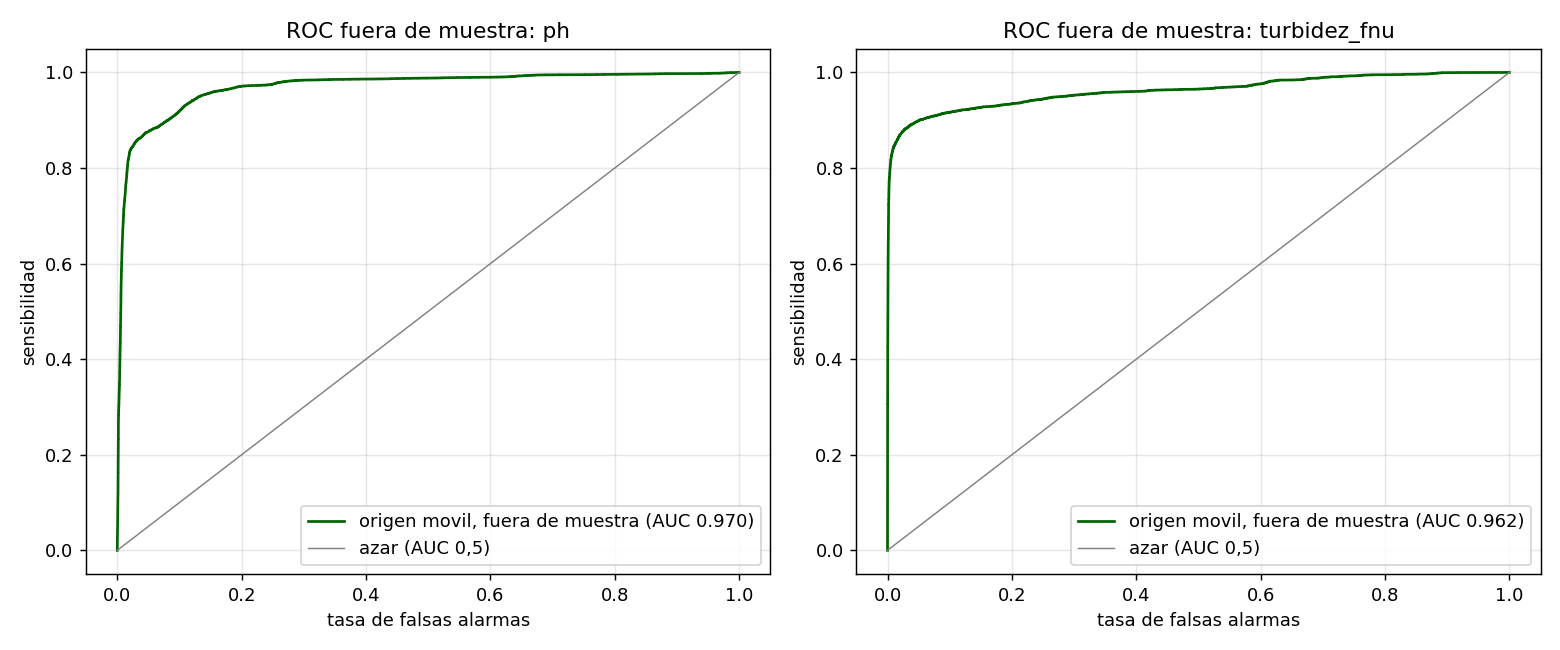

    variable     origen  filas  salidas_reales   AUC  precision_0.5  sensibilidad_0.5
          ph 2026-08-26  52841            3255 0.956            NaN               NaN
          ph 2026-09-10  52930            6857 0.975            NaN               NaN
          ph 2026-09-25  50836            5130 0.966            NaN               NaN
          ph 2026-10-10  53803            6026 0.977            NaN               NaN
          ph      TOTAL 210410           21268 0.970           0.45              0.95
turbidez_fnu 2026-08-26  52841            1598 0.960            NaN               NaN
turbidez_fnu 2026-09-10  52930            2170 0.917            NaN               NaN
turbidez_fnu 2026-09-25  50836             317 0.921            NaN               NaN
turbidez_fnu 2026-10-10  53803            5677 0.981            NaN               NaN
turbidez_fnu      TOTAL 210410            9762 0.962           0.86              0.83
ph: AUC fuera de muestra 0.97 con 21268 salidas reales

In [5]:
ORIGENES = [25, 40, 55, 70]          # dias desde el inicio del historial
VENTANA = 15 * 86400
FOLDS, CURVAS_MOV = [], {}
for v in VARIABLES:
    d = DS[v]
    t0 = d.agg(F.min("ts5")).first()[0]
    dirc, partes = DIRECCION[v], []
    for k, dia in enumerate(ORIGENES):
        a = t0 + dia * 86400
        train = d.where(F.col("ts5") + HORIZONTE * PASO <= a)
        prueba = d.where((F.col("ts5") > a) & (F.col("ts5") <= a + VENTANA))
        if prueba.limit(1).count() == 0: continue
        m = Pipeline(stages=[VectorAssembler(inputCols=columnas(v), outputCol="features", handleInvalid="skip"),
                             LinearRegression(featuresCol="features", labelCol="label", regParam=0.01)]).fit(train)
        s = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse").evaluate(m.transform(train))
        u = {r["estacion_id"]: (r["p05"], r["p95"]) for r in
             base.where((F.col("variable") == v) & (F.col("ts5") <= a)).groupBy("estacion_id")
                 .agg(F.percentile_approx("valor", 0.05).alias("p05"), F.percentile_approx("valor", 0.95).alias("p95")).collect()}
        p = m.transform(prueba).select("estacion_id", "label", "prediction").toPandas()
        p = p[p.estacion_id.isin(u)]
        p05 = p.estacion_id.map(lambda e: u[e][0]); p95 = p.estacion_id.map(lambda e: u[e][1])
        pa = 1 - ((p95 - p.prediction) / s).map(ncdf); pb = ((p05 - p.prediction) / s).map(ncdf)
        r = pa if dirc == "alta" else pb if dirc == "baja" else (pa + pb).clip(upper=1.0)
        y = (p.label > p95) if dirc == "alta" else (p.label < p05) if dirc == "baja" else ((p.label > p95) | (p.label < p05))
        t = pd.DataFrame({"riesgo": r.values, "y": y.astype(int).values})
        _, auc_k = roc(t)
        FOLDS.append({"variable": v, "origen": str(pd.to_datetime(a, unit="s").date()), "filas": len(t),
                      "salidas_reales": int(t.y.sum()), "AUC": None if auc_k is None else round(auc_k, 3)})
        partes.append(t)
    todo = pd.concat(partes)
    curva, auc = roc(todo)
    tp, fp, fn = en_umbral(todo)
    CURVAS_MOV[v] = (curva, auc)
    FOLDS.append({"variable": v, "origen": "TOTAL", "filas": len(todo), "salidas_reales": int(todo.y.sum()),
                  "AUC": None if auc is None else round(auc, 3),
                  "precision_0.5": round(tp / (tp + fp), 2) if tp + fp else None,
                  "sensibilidad_0.5": round(tp / (tp + fn), 2) if tp + fn else None})

fig, ejes = plt.subplots(1, len(VARIABLES), figsize=(6 * len(VARIABLES), 5))
for ax, v in zip(ejes, VARIABLES):
    curva, auc = CURVAS_MOV[v]
    if curva is not None:
        ax.plot(curva.fpr, curva.tpr, "-", color="darkgreen", label=f"origen movil, fuera de muestra (AUC {auc:.3f})")
    ax.plot([0, 1], [0, 1], color="gray", lw=0.8, label="azar (AUC 0,5)")
    ax.set_title(f"ROC fuera de muestra: {v}"); ax.set_xlabel("tasa de falsas alarmas"); ax.set_ylabel("sensibilidad")
    ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{SALIDA}/roc_movil_{ID}.png", dpi=130); plt.close()
display(Image(f"{SALIDA}/roc_movil_{ID}.png"))
TABLA_MOV = pd.DataFrame(FOLDS)
print(TABLA_MOV.to_string(index=False))
for r in TABLA_MOV[TABLA_MOV.origen == "TOTAL"].itertuples():
    print(f"{r.variable}: AUC fuera de muestra {r.AUC} con {r.salidas_reales} salidas reales en {r.filas} casos.")

### 2.2 Referencia: el corte único del 12b

El 12b separó entrenamiento y prueba con un solo corte (prueba = octubre). Si en ese mes no hubo salidas reales del rango, ahí la ROC no existe, y la tabla lo muestra. La fila de entrenamiento es optimista porque el modelo ya vio esos datos.

In [6]:
RES = []
for v in VARIABLES:
    for periodo in ("prueba", "entrenamiento"):
        t = tabla_riesgo(v, periodo)
        curva, auc = roc(t)
        tp, fp, fn = en_umbral(t)
        RES.append({"variable": v, "periodo": periodo, "filas": len(t), "salidas_reales": int(t.y.sum()),
                    "porcentaje": round(100 * t.y.mean(), 2), "AUC": None if auc is None else round(auc, 3),
                    "alertas_umbral_05": int(tp + fp), "aciertos": int(tp),
                    "precision": round(tp / (tp + fp), 2) if tp + fp else None,
                    "sensibilidad": round(tp / (tp + fn), 2) if tp + fn else None})
TABLA_ROC = pd.DataFrame(RES)
print(TABLA_ROC.to_string(index=False))

    variable       periodo  filas  salidas_reales  porcentaje   AUC  alertas_umbral_05  aciertos  precision  sensibilidad
          ph        prueba  64451            7837       12.16 0.977              12612      7504       0.59          0.96
          ph entrenamiento 250477           11090        4.43 0.971              28569     10028       0.35          0.90
turbidez_fnu        prueba  64451            3933        6.10 0.987               3769      3434       0.91          0.87
turbidez_fnu entrenamiento 250477           12018        4.80 0.932              10642      8799       0.83          0.73


In [7]:
for r in TABLA_ROC[TABLA_ROC.periodo == "prueba"].itertuples():
    if pd.isna(r.AUC):
        print(f"{r.variable}: en el periodo de prueba no hubo ninguna salida real del rango ({r.filas} casos). "
              "Con ese corte no hay ROC; por eso la principal es la de origen movil (2.1).")
    else:
        nivel = "excelente" if r.AUC >= 0.9 else "buena" if r.AUC >= 0.8 else "aceptable" if r.AUC >= 0.7 else "debil"
        print(f"{r.variable}: AUC {r.AUC} ({nivel}). Con umbral 0,5: {r.alertas_umbral_05} alertas, "
              f"precision {r.precision}, sensibilidad {r.sensibilidad}.")

ph: AUC 0.977 (excelente). Con umbral 0,5: 12612 alertas, precision 0.59, sensibilidad 0.96.
turbidez_fnu: AUC 0.987 (excelente). Con umbral 0,5: 3769 alertas, precision 0.91, sensibilidad 0.87.


## 3. Curva de aprendizaje

Se reentrena la misma regresión lineal con ventanas de entrenamiento cada vez más largas, siempre **terminando en el corte** (los datos más recientes), y se mide el RMSE en el mismo periodo de prueba. La línea horizontal es la persistencia.

- Si la curva de prueba **sigue bajando** al final, más historia ayudaría.
- Si **se aplana**, el modelo ya aprendió lo que podía con estas variables: para mejorar hacen falta otras variables, no más datos.
- Si **es mejor con menos días recientes**, el agua cambia con la estación: conviene reentrenar seguido con una ventana móvil.
- La curva de **entrenamiento** sube con más días porque una sola recta debe ajustar más estaciones del año; lo que importa es la de prueba.

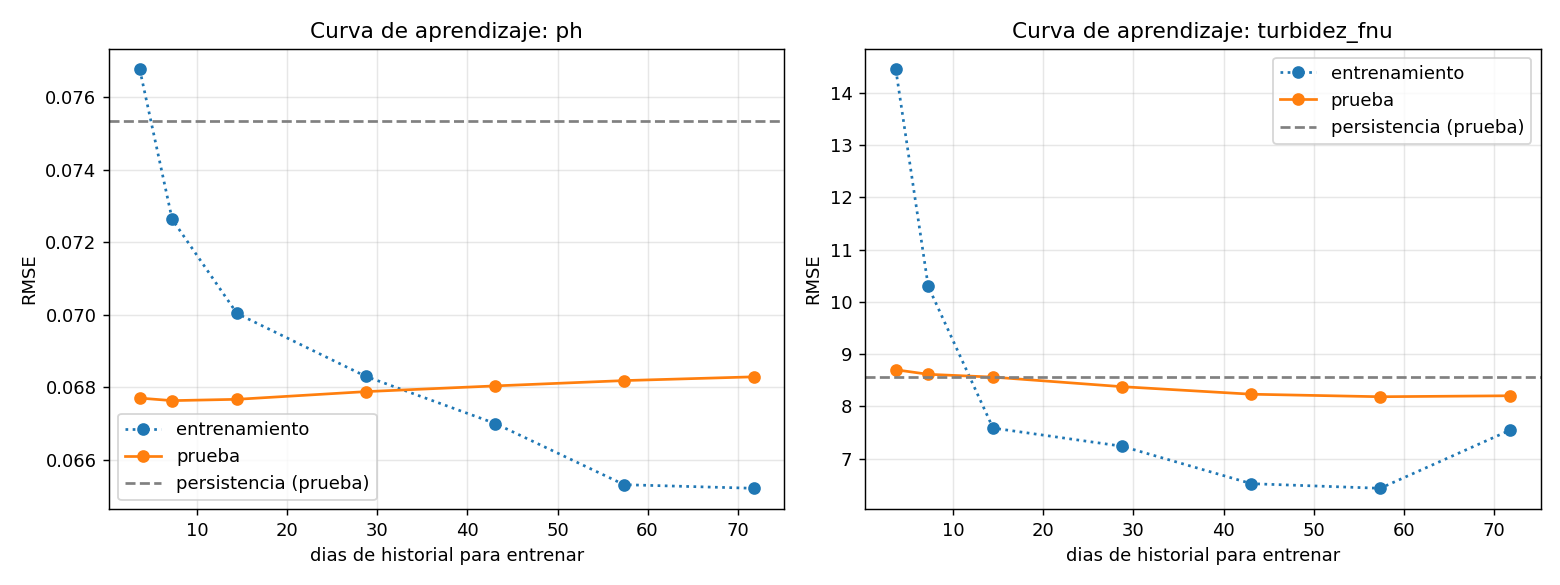

    variable  fraccion  dias  filas  RMSE_entrenamiento  RMSE_prueba  RMSE_persistencia
          ph      0.05   3.6  12943              0.0768       0.0677             0.0753
          ph      0.10   7.2  25723              0.0726       0.0676             0.0753
          ph      0.20  14.4  48843              0.0700       0.0677             0.0753
          ph      0.40  28.7  99158              0.0683       0.0679             0.0753
          ph      0.60  43.1 149868              0.0670       0.0680             0.0753
          ph      0.80  57.4 200321              0.0653       0.0682             0.0753
          ph      1.00  71.8 250477              0.0652       0.0683             0.0753
turbidez_fnu      0.05   3.6  12943             14.4466       8.6985             8.5651
turbidez_fnu      0.10   7.2  25723             10.2955       8.6122             8.5651
turbidez_fnu      0.20  14.4  48843              7.5826       8.5582             8.5651
turbidez_fnu      0.40  28.7  99

In [8]:
ev = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
FRACCIONES = [0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
CURVA = []
for v in VARIABLES:
    d = DS[v]
    train = d.where(F.col("ts5") + HORIZONTE * PASO <= CORTE)
    test = d.where(F.col("ts5") > CORTE).cache()
    t0 = train.agg(F.min("ts5")).first()[0]
    persist = ev.evaluate(test.withColumn("prediction", F.col(v)))
    for f in FRACCIONES:
        desde = CORTE - f * (CORTE - t0)
        sub = train.where(F.col("ts5") >= desde)
        m = Pipeline(stages=[VectorAssembler(inputCols=columnas(v), outputCol="features", handleInvalid="skip"),
                             LinearRegression(featuresCol="features", labelCol="label", regParam=0.01)]).fit(sub)
        CURVA.append({"variable": v, "fraccion": f, "dias": round(f * (CORTE - t0) / 86400, 1), "filas": sub.count(),
                      "RMSE_entrenamiento": ev.evaluate(m.transform(sub)), "RMSE_prueba": ev.evaluate(m.transform(test)),
                      "RMSE_persistencia": persist})
CURVA = pd.DataFrame(CURVA)
fig, ejes = plt.subplots(1, len(VARIABLES), figsize=(6 * len(VARIABLES), 4.5))
for ax, v in zip(ejes, VARIABLES):
    c = CURVA[CURVA.variable == v]
    ax.plot(c.dias, c.RMSE_entrenamiento, "o:", label="entrenamiento")
    ax.plot(c.dias, c.RMSE_prueba, "o-", label="prueba")
    ax.axhline(c.RMSE_persistencia.iloc[0], color="gray", ls="--", label="persistencia (prueba)")
    ax.set_title(f"Curva de aprendizaje: {v}"); ax.set_xlabel("dias de historial para entrenar"); ax.set_ylabel("RMSE")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{SALIDA}/aprendizaje_{ID}.png", dpi=130); plt.close()
display(Image(f"{SALIDA}/aprendizaje_{ID}.png"))
print(CURVA.round(4).to_string(index=False))

In [9]:
for v in VARIABLES:
    c = CURVA[CURVA.variable == v].reset_index(drop=True)
    ult, penult = c.RMSE_prueba.iloc[-1], c.RMSE_prueba.iloc[-2]
    cambio = 100 * (penult - ult) / penult
    mejor = c.loc[c.RMSE_prueba.idxmin()]
    if cambio > 2:
        tendencia = "todavia baja: mas historia ayudaria"
    elif mejor.fraccion < 1.0 and (ult - mejor.RMSE_prueba) / ult > 0.02:
        tendencia = (f"el mejor RMSE ({mejor.RMSE_prueba:.4f}) sale con solo {mejor.dias} dias recientes: el agua cambia con la "
                     "estacion y los datos recientes pesan mas; conviene reentrenar con una ventana movil")
    else:
        tendencia = "ya se aplano: para mejorar hacen falta otras variables, no mas datos"
    gana = "le gana" if ult < c.RMSE_persistencia.iloc[0] else "NO le gana"
    print(f"{v}: RMSE de prueba {c.RMSE_prueba.iloc[0]:.4f} con {c.dias.iloc[0]} dias -> {ult:.4f} con {c.dias.iloc[-1]} dias. "
          f"Ultimo tramo: {cambio:+.1f} %, {tendencia}. Con todo el historial {gana} a la persistencia ({c.RMSE_persistencia.iloc[0]:.4f}).")
json.dump({"roc_corte_unico": TABLA_ROC.to_dict("records"), "roc_origen_movil": TABLA_MOV.to_dict("records"), "aprendizaje": CURVA.to_dict("records")},
          open(f"{SALIDA}/evaluacion_{ID}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, default=float)
print("Guardado en", SALIDA, os.listdir(SALIDA))

ph: RMSE de prueba 0.0677 con 3.6 dias -> 0.0683 con 71.8 dias. Ultimo tramo: -0.2 %, ya se aplano: para mejorar hacen falta otras variables, no mas datos. Con todo el historial le gana a la persistencia (0.0753).
turbidez_fnu: RMSE de prueba 8.6985 con 3.6 dias -> 8.2011 con 71.8 dias. Ultimo tramo: -0.2 %, ya se aplano: para mejorar hacen falta otras variables, no mas datos. Con todo el historial le gana a la persistencia (8.5651).
Guardado en /opt/s12-u2-usgs/artifacts/evaluacion_jhenderson ['aprendizaje_jhenderson.png', 'evaluacion_jhenderson.json', 'roc_jhenderson.png', 'roc_movil_jhenderson.png']
